In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label

In [4]:
dataset = build_dataset('test')

In [5]:
unet_baseline = ModelResults('207-deeplabv3plus', 'unet', 199, 'test', dataset)

In [6]:
baseline = ModelResults('212-beamdiff-mp', 'ddpm-1000', 199, 'test', dataset)
merged_all = ModelResults('217-merged-all', 'ddpm-1000', 199, 'test', dataset)
merged_conditition = ModelResults('218-merged-condition', 'ddpm-1000', 199, 'test', dataset)
no_mam = ModelResults('219-no-mam', 'ddpm-1000', 199, 'test', dataset)
no_afm = ModelResults('220-no-afm', 'ddpm-1000', 199, 'test', dataset)
no_self_attn = ModelResults('221-no-self-attn', 'ddpm-1000', 199, 'test', dataset)
base_channels_64 = ModelResults('222-base-channels-64', 'ddpm-1000', 199, 'test', dataset)
res_blocks_1 = ModelResults('223-res-blocks-1', 'ddpm-1000', 199, 'test', dataset)
channels_1123 = ModelResults('224-channels-1123', 'ddpm-1000', 199, 'test', dataset)
channels_11123 = ModelResults('225-channels-11123', 'ddpm-1000', 199, 'test', dataset)
optimised_arch = ModelResults('226-optimised-arch', 'ddpm-1000', 199, 'test', dataset)

In [7]:
comparison = ModelComparison(
  [baseline, merged_all, merged_conditition, no_mam, no_afm, no_self_attn, base_channels_64, res_blocks_1, channels_1123, channels_11123, optimised_arch],
  ['Baseline', 'Merged All', 'Merged Condition', 'No MAM', 'No AFM', 'No Self-Attn', 'Base Channels 64', 'Res Blocks 1', 'Channels 1123', 'Channels 11123', 'Optimised Arch']
)

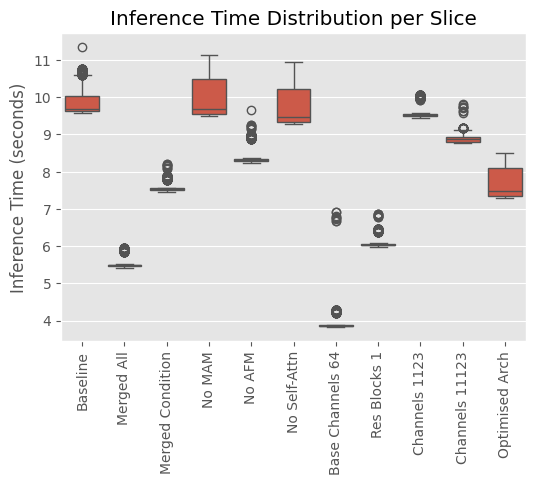

In [8]:
_ = comparison.plot_inference_times('slice', 'seconds')

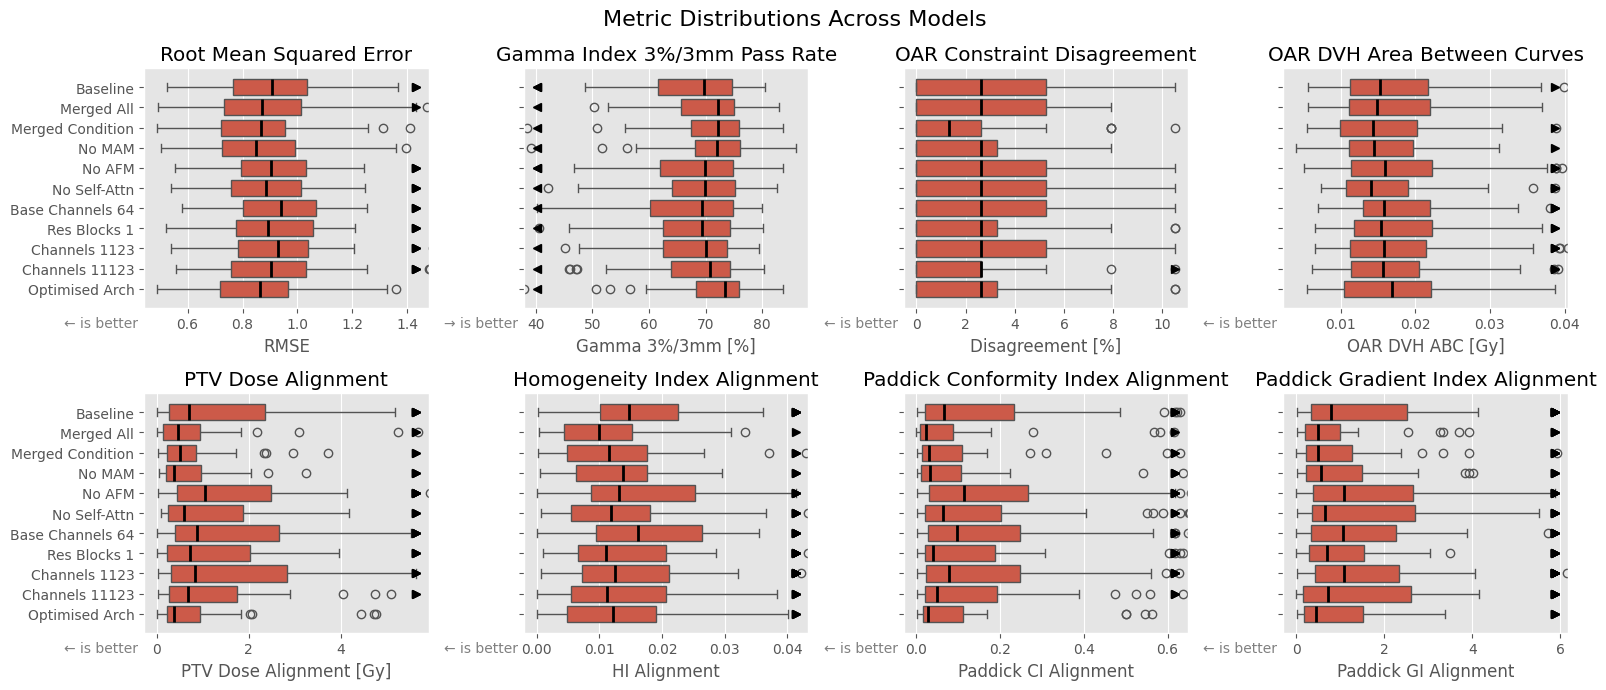

In [9]:
_ = comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, outliers=False)

In [10]:
import numpy as np

def plot_improvement_heatmap(comparison, metrics, baseline_result=None, mode='combined', sort_by='net_total', ax=None):
    """
    Create a heatmap showing volume improvement/worsening counts per metric.

    Args:
        comparison: ModelComparison object
        metrics: List of metric names to include
        baseline_result: ModelResults to compare against. If None, uses first model in comparison.
        mode: 'improved', 'worsened', or 'combined' (shows net with ↑/↓ annotations)
        sort_by: How to sort models. Options:
            - 'net_total': Total net improvement across all metrics (default)
            - 'net_avg': Average net improvement per metric
            - 'improvements': Total number of improvements
            - 'worst_metric': Best worst-case metric
            - <metric_name>: Sort by a specific metric
            - None: Keep original order
        ax: Optional matplotlib axes

    Returns:
        Matplotlib axes
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(len(metrics) * 1.5 + 2, len(comparison.results_list) * 0.5 + 2))

    # Get baseline metrics
    if baseline_result is None:
        baseline_metrics = comparison.results_list[0].volume_metrics.set_index('file_name')
        models_to_compare = comparison.results_list[1:]
        labels_to_compare = list(comparison.result_labels[1:])
    else:
        baseline_metrics = baseline_result.volume_metrics.set_index('file_name')
        models_to_compare = comparison.results_list
        labels_to_compare = list(comparison.result_labels)

    n_volumes = len(baseline_metrics)

    # Build counts matrices
    improvement_counts = []
    worsening_counts = []

    for result in models_to_compare:
        model_metrics = result.volume_metrics.set_index('file_name')
        improved_row = []
        worsened_row = []

        for metric in metrics:
            if metric not in baseline_metrics.columns or metric not in model_metrics.columns:
                improved_row.append(0)
                worsened_row.append(0)
                continue

            # Align indices
            common_idx = baseline_metrics.index.intersection(model_metrics.index)
            baseline_vals = baseline_metrics.loc[common_idx, metric]
            model_vals = model_metrics.loc[common_idx, metric]

            # Count improvements/worsenings based on metric direction
            if is_higher_better(metric):
                improved = (model_vals > baseline_vals).sum()
                worsened = (model_vals < baseline_vals).sum()
            else:
                improved = (model_vals < baseline_vals).sum()
                worsened = (model_vals > baseline_vals).sum()

            improved_row.append(improved)
            worsened_row.append(worsened)

        improvement_counts.append(improved_row)
        worsening_counts.append(worsened_row)

    # Sort models based on sort_by parameter
    improvement_counts = np.array(improvement_counts)
    worsening_counts = np.array(worsening_counts)
    net = improvement_counts - worsening_counts

    if sort_by == 'net_total':
        sort_idx = np.argsort(-net.sum(axis=1))
    elif sort_by == 'net_avg':
        sort_idx = np.argsort(-net.mean(axis=1))
    elif sort_by == 'improvements':
        sort_idx = np.argsort(-improvement_counts.sum(axis=1))
    elif sort_by == 'worst_metric':
        sort_idx = np.argsort(-net.min(axis=1))
    elif sort_by in metrics:
        metric_idx = metrics.index(sort_by)
        sort_idx = np.argsort(-net[:, metric_idx])
    else:
        sort_idx = np.arange(len(labels_to_compare))

    # Reorder data
    labels_to_compare = [labels_to_compare[i] for i in sort_idx]
    improvement_counts = improvement_counts[sort_idx]
    worsening_counts = worsening_counts[sort_idx]

    metric_abbrs = [get_metric_abbr(m) for m in metrics]

    if mode == 'improved':
        df = pd.DataFrame(improvement_counts, index=labels_to_compare, columns=metric_abbrs)
        sns.heatmap(df, annot=True, fmt='d', cmap='RdYlGn', center=n_volumes/2,
                    vmin=0, vmax=n_volumes, ax=ax, cbar_kws={'label': f'Volumes improved (of {n_volumes})'})
        ax.set_title('Number of volumes improved per metric')

    elif mode == 'worsened':
        df = pd.DataFrame(worsening_counts, index=labels_to_compare, columns=metric_abbrs)
        sns.heatmap(df, annot=True, fmt='d', cmap='RdYlGn_r', center=n_volumes/2,
                    vmin=0, vmax=n_volumes, ax=ax, cbar_kws={'label': f'Volumes worsened (of {n_volumes})'})
        ax.set_title('Number of volumes worsened per metric')

    elif mode == 'combined':
        # Net improvement for coloring
        net = improvement_counts - worsening_counts
        df_net = pd.DataFrame(net, index=labels_to_compare, columns=metric_abbrs)

        # Create annotation strings "↑X ↓Y"
        annot = []
        for i in range(len(improvement_counts)):
            row = []
            for j in range(len(metrics)):
                row.append(f"↑{improvement_counts[i][j]} ↓{worsening_counts[i][j]}")
            annot.append(row)
        annot_df = pd.DataFrame(annot, index=labels_to_compare, columns=metric_abbrs)

        sns.heatmap(df_net, annot=annot_df, fmt='', cmap='RdYlGn', center=0,
                    vmin=-n_volumes, vmax=n_volumes, ax=ax,
                    cbar_kws={'label': f'Net improvement (of {n_volumes} volumes)'})
        ax.set_title('Volume changes per metric (↑improved ↓worsened)')

    ax.set_xlabel('Metric')
    ax.set_ylabel('Model')

    return ax

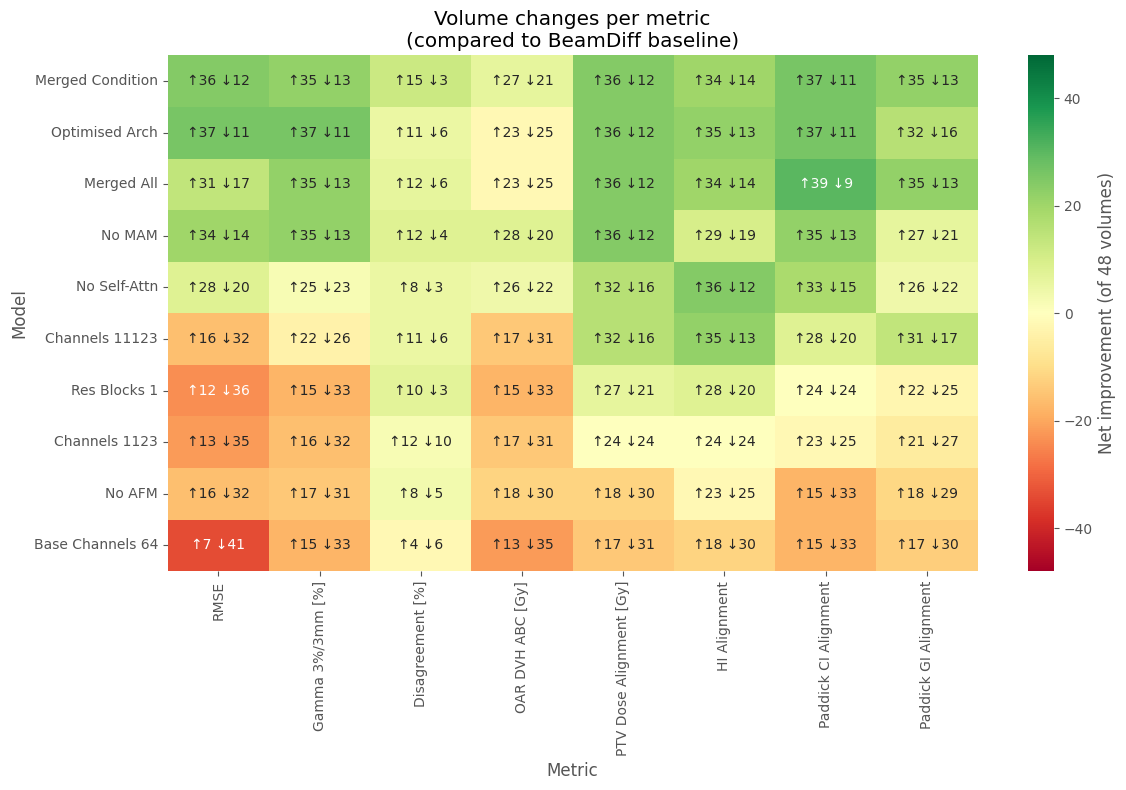

In [11]:
fig, ax = plt.subplots(figsize=(12, 8))
_ = plot_improvement_heatmap(comparison - baseline, METRICS_PLAN_EXTENDED, baseline_result=baseline, mode='combined', ax=ax)
ax.set_title('Volume changes per metric\n(compared to BeamDiff baseline)')
plt.tight_layout()